# Fabric transmittance and absorbance

1. Set up access to the measurement files.
2. Calculate absorbance and specular transmission spectra.
3. Calculate luminous specular transmission.
4. Run supplemental optical and image comparisons.

For luminous specular transmission, run “Specular transmission spectra” first or point the luminous calculation to an existing `T_specular.xlsx`.

## 1. Set up data access

### Mount Google Drive in Colab

The input and output paths point to `/content/drive/MyDrive/Master`. Run this cell first in Colab.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Calculate spectral quantities

### Absorbance spectra

Combine transmission measurements from multiple Excel files, convert percentages to fractions, and calculate absorbance as −log₁₀(T). Save the data and spectra plot.

Loaded /content/drive/MyDrive/Master/New white 27th july/White transmittance white instrument.xlsx
  -> 1 samples x 31 wavelengths
Loaded /content/drive/MyDrive/Master/New white 27th july/White transmittance black instrument.xlsx
  -> 1 samples x 31 wavelengths

Combined: 2 total samples x 31 wavelengths
                                                     400.0   410.0   420.0  \
white-white instrument (White transmittance whi...  97.328  94.744  93.236   
white-black instrument (White transmittance bla...  74.582  71.915  70.526   

                                                     430.0   440.0   450.0  \
white-white instrument (White transmittance whi...  91.970  91.329  90.588   
white-black instrument (White transmittance bla...  69.353  68.579  67.878   

                                                     460.0   470.0   480.0  \
white-white instrument (White transmittance whi...  90.122  89.475  89.155   
white-black instrument (White transmittance bla...  67.440  66.971  

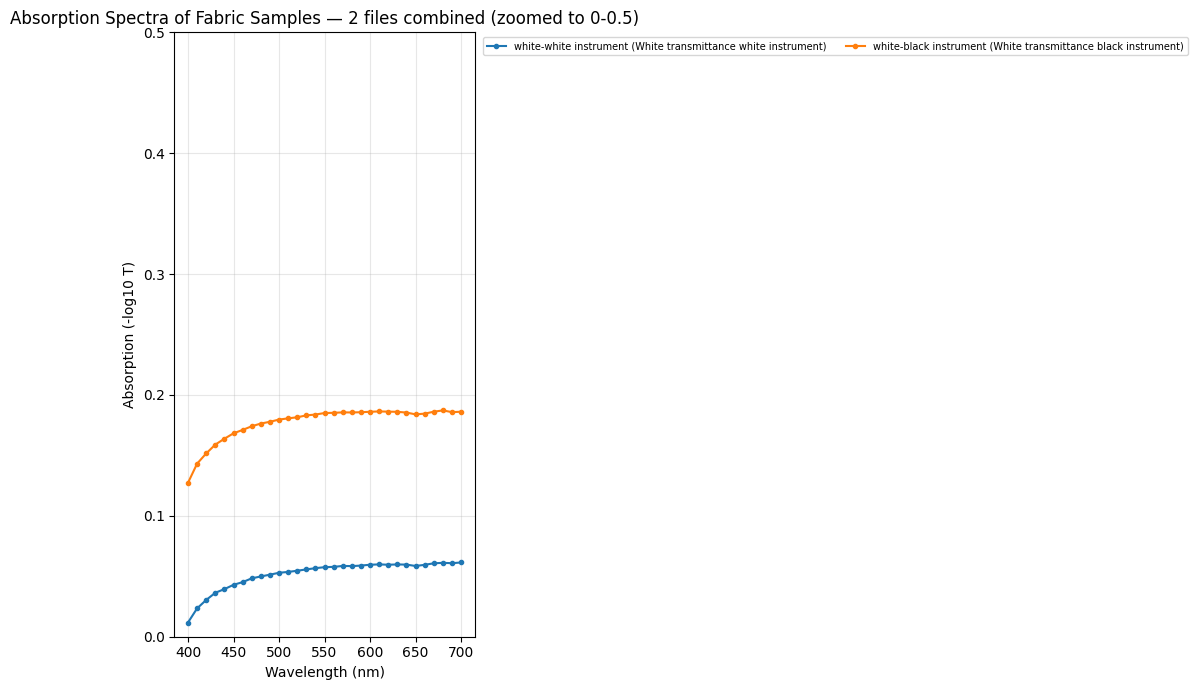

Saved plot to /content/drive/MyDrive/Master/absorption_spectra_combined.png


In [ ]:
"""
Compute absorption spectra from fabric transmission data — multiple Excel files.

Expected Excel layout (same for every input file):
- Row 1: header (e.g. REFLECT05...REFLECT35), columns B:AF (32 cols total, data starts col 2)
- Column A: sample names, data starts row 2 (rows 2-15 -> 14 samples)
- Data block: rows 2-15, columns 2-32 (31 wavelengths, 400-700 nm)
- Values are in percent transmission (0-100)

Steps:
1. Load the data block from each file in INPUT_FILES
2. Combine all files into one table (samples stacked; filename tag added
   to each sample name so duplicates across files stay distinguishable)
3. Divide by 100 -> transmission fraction (0-1)
4. Absorption = -log10(Transmission)
5. Plot all samples' absorption spectra together, zoomed to y = 0-0.5
   (most samples fall in this range; two instrument/calibration rows
   will go off-chart, which is expected and left in the legend)
"""

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------------
# CONFIG - edit these
# ---------------------------------------------------------------
INPUT_FILES = [
    "/content/drive/MyDrive/Master/New white 27th july/White transmittance white instrument.xlsx",
    "/content/drive/MyDrive/Master/New white 27th july/White transmittance black instrument.xlsx",
    # add as many files as you need here
]
SHEET_NAME = 0                          # sheet name or index, applied to every file

OUTPUT_FILE = "/content/drive/MyDrive/Master/absorption_results_combined.xlsx"
PLOT_FILE = "/content/drive/MyDrive/Master/absorption_spectra_combined.png"

WAVELENGTH_START = 400
WAVELENGTH_END = 700
N_WAVELENGTHS = 31                      # 400 to 700 nm in steps of 10 nm
N_SAMPLES = 14                          # rows 2-15 in each Excel file

Y_AXIS_LIMIT = (0, 0.5)                 # zoom range for the plot

# Tag sample names with the source filename so identical sample names in
# different files don't get silently merged/overwritten.
TAG_SAMPLE_NAMES_WITH_FILENAME = True

# ---------------------------------------------------------------
# 1. LOAD DATA FROM EACH FILE
# ---------------------------------------------------------------
wavelengths = np.linspace(WAVELENGTH_START, WAVELENGTH_END, N_WAVELENGTHS)

all_dfs = []
for path in INPUT_FILES:
    df_raw = pd.read_excel(path, sheet_name=SHEET_NAME, header=0, index_col=0)

    # Data block: first N_SAMPLES rows, first N_WAVELENGTHS columns after the index
    df_raw = df_raw.iloc[:N_SAMPLES, :N_WAVELENGTHS]
    df_raw.columns = wavelengths

    if TAG_SAMPLE_NAMES_WITH_FILENAME:
        tag = os.path.splitext(os.path.basename(path))[0]
        df_raw.index = [f"{name} ({tag})" for name in df_raw.index]

    print(f"Loaded {path}")
    print(f"  -> {df_raw.shape[0]} samples x {df_raw.shape[1]} wavelengths")

    all_dfs.append(df_raw)

# Combine all files into one table (stacked by rows/samples)
df_combined = pd.concat(all_dfs, axis=0)

# Warn about duplicate sample names (e.g. if tagging is off and two files
# reuse the same sample name — later rows would silently coexist as
# duplicate index entries, not overwrite, but worth flagging)
dupes = df_combined.index[df_combined.index.duplicated()].unique()
if len(dupes) > 0:
    print(f"WARNING: duplicate sample names found across files: {list(dupes)}")

print(f"\nCombined: {df_combined.shape[0]} total samples x {df_combined.shape[1]} wavelengths")
print(df_combined.head())

# ---------------------------------------------------------------
# 2. NORMALIZE (percent -> fraction 0-1)
# ---------------------------------------------------------------
df_transmission = df_combined / 100.0

# ---------------------------------------------------------------
# 3. COMPUTE ABSORPTION: A = -log10(T)
# ---------------------------------------------------------------
# Guard against zero/negative values which would break log10
df_transmission_clipped = df_transmission.clip(lower=1e-6)
df_absorption = -np.log10(df_transmission_clipped)

# ---------------------------------------------------------------
# 4. SAVE RESULTS
# ---------------------------------------------------------------
with pd.ExcelWriter(OUTPUT_FILE, engine="openpyxl") as writer:
    df_transmission.to_excel(writer, sheet_name="Transmission (0-1)")
    df_absorption.to_excel(writer, sheet_name="Absorption")

print(f"\nSaved combined transmission + absorption data to {OUTPUT_FILE}")
print("NOTE: the file has TWO sheets - 'Transmission (0-1)' and 'Absorption'.")

# ---------------------------------------------------------------
# 5. PLOT ALL SAMPLES TOGETHER (zoomed y-axis)
# ---------------------------------------------------------------
plt.figure(figsize=(11, 7))

for sample_name, row in df_absorption.iterrows():
    plt.plot(wavelengths, row.values, marker="o", markersize=3, label=str(sample_name))

plt.ylim(*Y_AXIS_LIMIT)
plt.xlabel("Wavelength (nm)")
plt.ylabel("Absorption (-log10 T)")
plt.title(f"Absorption Spectra of Fabric Samples — {len(INPUT_FILES)} files combined "
          f"(zoomed to {Y_AXIS_LIMIT[0]}-{Y_AXIS_LIMIT[1]})")
plt.legend(loc="upper left", fontsize=7, ncol=2, bbox_to_anchor=(1.01, 1))
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(PLOT_FILE, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved plot to {PLOT_FILE}")

### Specular transmission spectra

Subtract diffuse transmission from total transmission at each wavelength. Save all three spectra to `T_specular.xlsx`.

In [ ]:
"""
Compute specular transmission = T_total - T_diffuse, wavelength by wavelength,
for each sample.

Expected Excel layout (same for both files):
- Row 1: header (wavelength labels, e.g. REFLECT05...REFLECT35)
- Column A: sample names
- Data block: numeric transmission values (percent, 0-100) across wavelengths
- Sample names and wavelength columns must match between the two files

Note: TOTAL_FILE and DIFFUSE_FILE are the SAME fabric samples, measured
twice with different instrument backing (white backing -> total
transmission, black backing -> diffuse transmission). File names differ
only by "white"/"black instrument", not by sample set.
"""

import pandas as pd
import numpy as np

# ---------------------------------------------------------------
# CONFIG - edit these
# ---------------------------------------------------------------
TOTAL_FILE = "/content/drive/MyDrive/Master/New white 27th july/White transmittance white instrument.xlsx"
DIFFUSE_FILE = "/content/drive/MyDrive/Master/New white 27th july/White transmittance black instrument.xlsx"
OUTPUT_FILE = "/content/drive/MyDrive/Master/New white 27th july/T_specular.xlsx"

# ---------------------------------------------------------------
# 1. LOAD DATA
# ---------------------------------------------------------------
df_total = pd.read_excel(TOTAL_FILE, sheet_name=0, header=0, index_col=0)
df_diffuse = pd.read_excel(DIFFUSE_FILE, sheet_name=0, header=0, index_col=0)

print("T_total shape:", df_total.shape)
print("T_diffuse shape:", df_diffuse.shape)

# ---------------------------------------------------------------
# 1b. NORMALIZE (percent 0-100 -> fraction 0-1)
# ---------------------------------------------------------------
df_total = df_total / 100.0
df_diffuse = df_diffuse / 100.0

# ---------------------------------------------------------------
# 2. SANITY CHECK: same samples, same wavelengths, same order
# ---------------------------------------------------------------
if not df_total.index.equals(df_diffuse.index):
    raise ValueError(
        "Sample names/order differ between the two files. "
        "Check for typos, extra rows, or different row ordering."
    )

if not df_total.columns.equals(df_diffuse.columns):
    raise ValueError(
        "Wavelength columns differ between the two files. "
        "Check headers match exactly."
    )

# ---------------------------------------------------------------
# 3. COMPUTE SPECULAR TRANSMISSION
# ---------------------------------------------------------------
df_specular = df_total - df_diffuse

# Optional: specular transmission physically can't be negative or exceed T_total.
# Flag any rows/values where this happens (measurement noise or misalignment).
negative_mask = df_specular < 0
if negative_mask.any().any():
    print("WARNING: negative specular values found (check these samples/wavelengths):")
    print(df_specular[negative_mask.any(axis=1)])

# ---------------------------------------------------------------
# 4. SAVE RESULTS
# ---------------------------------------------------------------
with pd.ExcelWriter(OUTPUT_FILE, engine="openpyxl") as writer:
    df_total.to_excel(writer, sheet_name="T_total")
    df_diffuse.to_excel(writer, sheet_name="T_diffuse")
    df_specular.to_excel(writer, sheet_name="T_specular")

print(f"Saved results to {OUTPUT_FILE}")

T_total shape: (1, 31)
T_diffuse shape: (1, 31)
Saved results to /content/drive/MyDrive/Master/New white 27th july/T_specular.xlsx


## 3. Calculate luminous specular transmission

### Inspect the photopic sensitivity samples

Read the photopic sensitivity curve and select 31 values at 10 nm intervals to check the wavelength grid.

In [ ]:
import pandas as pd
import numpy as np

# ---------------------------------------------------------------
# CONFIG - edit these
# ---------------------------------------------------------------
PHOTOPIC_FILE = "/content/drive/MyDrive/Master/CIE_sle_photopic (1).xlsx"   # path to your Excel file
SHEET_NAME = 0
WAVELENGTH_COL = 0   # column A holds wavelength
VALUE_COL = 1        # column B holds V(lambda)

# Excel row numbers are 1-indexed. File has NO header, so Excel row 1 = pandas iloc 0.
# Excel row 41 -> pandas iloc index 40
# Excel row 341 -> pandas iloc index 340
EXCEL_START_ROW = 41
EXCEL_END_ROW = 341

# ---------------------------------------------------------------
# 1. LOAD DATA
# ---------------------------------------------------------------
df = pd.read_excel(PHOTOPIC_FILE, sheet_name=SHEET_NAME, header=None)

start_idx = EXCEL_START_ROW - 1   # no header row, so Excel row 1 = index 0
end_idx = EXCEL_END_ROW - 1       # inclusive

df_photopic = df.iloc[start_idx:end_idx + 1, [WAVELENGTH_COL, VALUE_COL]]
df_photopic.columns = ["wavelength", "V"]

print(f"Loaded {df_photopic.shape[0]} rows (expected 301 for 400-700nm at 1nm steps)")
print(df_photopic.head())
print(df_photopic.tail())

# ---------------------------------------------------------------
# 2. DOWNSAMPLE TO EVERY 10th WAVELENGTH (301 points -> 31 points)
# ---------------------------------------------------------------
df_photopic_31 = df_photopic.iloc[::10].reset_index(drop=True)

print(f"\nDownsampled to {df_photopic_31.shape[0]} points (expected 31)")
print(df_photopic_31)

V = df_photopic_31["V"].to_numpy().reshape(-1, 1)   # shape (31, 1), ready to use as V(lambda)

Loaded 301 rows (expected 301 for 400-700nm at 1nm steps)
    wavelength         V
40         400  0.000396
41         401  0.000434
42         402  0.000473
43         403  0.000518
44         404  0.000572
     wavelength         V
336         696  0.005343
337         697  0.004996
338         698  0.004676
339         699  0.004380
340         700  0.004102

Downsampled to 31 points (expected 31)
    wavelength         V
0          400  0.000396
1          410  0.001210
2          420  0.004000
3          430  0.011600
4          440  0.023000
5          450  0.038000
6          460  0.060000
7          470  0.090980
8          480  0.139020
9          490  0.208020
10         500  0.323000
11         510  0.503000
12         520  0.710000
13         530  0.862000
14         540  0.954000
15         550  0.994950
16         560  0.995000
17         570  0.952000
18         580  0.870000
19         590  0.757000
20         600  0.631000
21         610  0.503000
22         620  0.381

### Weight specular transmission by D65 and photopic sensitivity

Read the `T_specular` sheet created in section 2 and load the weighting data within this cell. Save the weighted result for each sample in `luminous_transmittance_specular_report.xlsx`.

In [ ]:
import pandas as pd
import numpy as np
from scipy.io import loadmat

# ---------------------------------------------------------------
# CONFIG - edit these
# ---------------------------------------------------------------
SPECULAR_FILE = "/content/drive/MyDrive/Master/New white 27th july/T_specular.xlsx"   # the file saved earlier, with sheets T_total/T_diffuse/T_specular
SPECULAR_SHEET = "T_specular"       # already in 0-1 scale, no need to divide by 100 again

PHOTOPIC_FILE = "/content/drive/MyDrive/Master/CIE_sle_photopic (1).xlsx"
MAT_FILE = "/content/drive/MyDrive/Master/exe_4.mat"

OUTPUT_FILE = "/content/drive/MyDrive/Master/New white 27th july/luminous_transmittance_specular_report.xlsx"

# ---------------------------------------------------------------
# 1. LOAD T_specular DATA (already 0-1 scale)
# ---------------------------------------------------------------
df_specular = pd.read_excel(SPECULAR_FILE, sheet_name=SPECULAR_SHEET, header=0, index_col=0)

sample_names = df_specular.index.tolist()
T_specular = df_specular.to_numpy()   # shape (n_samples, 31), already 0-1

print("T_specular shape:", T_specular.shape)
print(df_specular.head())

# ---------------------------------------------------------------
# 2. LOAD PHOTOPIC FUNCTION V(lambda), DOWNSAMPLED TO 31 POINTS
# ---------------------------------------------------------------
df_photopic = pd.read_excel(PHOTOPIC_FILE, sheet_name=0, header=None)
df_photopic = df_photopic.iloc[40:341, [0, 1]]      # Excel rows 41-341, no header
df_photopic.columns = ["wavelength", "V"]
df_photopic_31 = df_photopic.iloc[::10].reset_index(drop=True)

V = df_photopic_31["V"].to_numpy().reshape(-1, 1)   # shape (31, 1)

# ---------------------------------------------------------------
# 3. LOAD D65
# ---------------------------------------------------------------
data = loadmat(MAT_FILE)
D65 = data['D65'].reshape(-1, 1)   # shape (31, 1)

# ---------------------------------------------------------------
# 4. COMPUTE LUMINOUS TRANSMITTANCE
#
#           sum( T(lambda) * V(lambda) * D65(lambda) )
#    T_v = ---------------------------------------------
#                sum( V(lambda) * D65(lambda) )
# ---------------------------------------------------------------
denom = np.sum(V * D65)

def luminous_transmittance(T_matrix):
    T_v_list = []
    for i in range(T_matrix.shape[0]):
        T_lambda = T_matrix[i, :].reshape(-1, 1)
        numer = np.sum(T_lambda * V * D65)
        T_v_list.append(numer / denom)
    return np.array(T_v_list).flatten()

T_v_specular = luminous_transmittance(T_specular)

# ---------------------------------------------------------------
# 5. BUILD REPORT
# ---------------------------------------------------------------
report_df = pd.DataFrame({
    'Sample': sample_names,
    'T_v_specular': T_v_specular
})

report_df.to_excel(OUTPUT_FILE, index=False)
print(f"\nSaved luminous transmittance (specular) report to {OUTPUT_FILE}")
print(report_df)

T_specular shape: (1, 31)
       REFLECT05  REFLECT06  REFLECT07  REFLECT08  REFLECT09  REFLECT10  \
NAME                                                                      
white    0.22746    0.22829     0.2271    0.22617     0.2275     0.2271   

       REFLECT11  REFLECT12  REFLECT13  REFLECT14  ...  REFLECT26  REFLECT27  \
NAME                                               ...                         
white    0.22682    0.22504    0.22529    0.22448  ...    0.22026    0.22052   

       REFLECT28  REFLECT29  REFLECT30  REFLECT31  REFLECT32  REFLECT33  \
NAME                                                                      
white    0.21984    0.21916    0.21922     0.2182    0.21807    0.21895   

       REFLECT34  REFLECT35  
NAME                         
white    0.21733    0.21672  

[1 rows x 31 columns]

Saved luminous transmittance (specular) report to /content/drive/MyDrive/Master/New white 27th july/luminous_transmittance_specular_report.xlsx
  Sample  T_v_specular


## 4. Run supplemental optical and image comparisons

These analyses use their own inputs. The same code appears in the [optical–image statistics notebook](../03_optical_image_statistics/Given%20matlab%20code.ipynb).

### Two-lace correlation report

Combine spectral measurements and fabric photographs to compare direct transmission, diffuseness, and opacity with SSIM, edge acutance, and Michelson contrast.

In [5]:
"""
Python replication of code2mardasi.m — exact structural match, with
auto-discovered images and name-sorted spectrophotometric data.

Section 1: optical parameters from spectrophotometric data
    weighted_T_tot, weighted_T_diff, weighted_T_dir, diffuseness
    weighted_R_b, weighted_R_w, opacity

Section 2: ROI-based image quality metrics
    SSIM, Acutance (mean Sobel gradient magnitude), Michelson contrast

Section 3: cross-correlation between optical parameters and image metrics
    R matrix + p-values, matching MATLAB's corr(X, Y)

ALIGNMENT STRATEGY (this is the part that changed from the previous
version): images are no longer listed by hand -- they're discovered from
IMG_FOLDER and sorted alphabetically by filename. Each Excel sheet
(T_tot/T_diff/R_w/R_b) is independently sorted alphabetically by its
sample-name index. As long as both sides are sorted the same way (A-Z by
name), row k of the sorted Excel data and image k of the sorted image
list describe the same fabric -- this is safer than relying on whatever
order rows/files happened to be in originally. The two sorted lists are
printed side-by-side before anything else runs so you can visually
confirm they actually match before trusting the results.

No /100 normalization anywhere -- matches the MATLAB script exactly. If
your Excel files are on a 0-100 percent scale, values here will be 100x
the equivalent 0-1 fraction used elsewhere in this project; confirm which
scale your actual files use before comparing against other scripts.
"""

import os
import glob
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim_func
from scipy.stats import pearsonr
from scipy.io import loadmat

# ---------------------------------------------------------------
# CONFIG - edit these
# ---------------------------------------------------------------
TOTAL_FILE   = "/content/drive/MyDrive/Master/Data 9th September/Nonwoven + 2 lace Transmittance on white.xlsx"
DIFFUSE_FILE = "/content/drive/MyDrive/Master/Data 9th September/Nonwoven + 2 lace Tranmsittance on black.xlsx"
R_WHITE_FILE = "/content/drive/MyDrive/Master/Data 9th September/Nonwoven + 2 lace Reflection on white.xlsx"
R_BLACK_FILE = "/content/drive/MyDrive/Master/Data 9th September/Nonwoven + 2 lace Reflection on black.xlsx"

PHOTOPIC_FILE = "/content/drive/MyDrive/Master/CIE_sle_photopic (1).xlsx"
MAT_FILE = "/content/drive/MyDrive/Master/exe_4.mat"

IMG_FOLDER = "/content/drive/MyDrive/Master/Images 6th September(nonwoven + 2 layer lace)"
REFERENCE_IMG_NAME = "/content/drive/MyDrive/Master/Images 6th September(nonwoven + 2 layer lace)/No fabric cabinet.JPG"   # excluded from auto-discovery
IMAGE_EXTENSIONS = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")

OUTPUT_DIR = IMG_FOLDER

# ---------------------------------------------------------------
# HELPERS
# ---------------------------------------------------------------
def find_fabric_images(folder, reference_filename):
    """
    Scan `folder` for image files, sorted alphabetically (case-insensitive)
    by filename. Skips the reference image and skips any subfolders.
    """
    candidates = []
    for ext in IMAGE_EXTENSIONS:
        candidates.extend(glob.glob(os.path.join(folder, f"*{ext}")))
        candidates.extend(glob.glob(os.path.join(folder, f"*{ext.upper()}")))
    candidates = list(set(candidates))

    ref_path = os.path.join(folder, reference_filename)
    fabric_paths = [
        p for p in candidates
        if os.path.isfile(p)                                   # skip subfolders
        and os.path.abspath(p) != os.path.abspath(ref_path)     # skip reference image
    ]
    fabric_paths.sort(key=lambda p: os.path.basename(p).lower())
    return fabric_paths


def sample_title(path):
    """'.../White cabinet.JPG' -> 'White cabinet' -- used only for display."""
    return os.path.splitext(os.path.basename(path))[0]


def load_sorted(path):
    """Load an Excel sheet and sort its rows alphabetically (case-
    insensitive) by the sample-name index, so row order no longer depends
    on how the sheet happened to be entered."""
    df = pd.read_excel(path, header=0, index_col=0)
    df = df.loc[sorted(df.index, key=lambda name: str(name).strip().lower())]
    return df


def imread_gray(path):
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float64)


# ---------------------------------------------------------------
# SECTION 0: DISCOVER IMAGES, LOAD + SORT EXCEL DATA, CHECK ALIGNMENT
# ---------------------------------------------------------------
IMG_FILES = find_fabric_images(IMG_FOLDER, REFERENCE_IMG_NAME)
IMG_TITLES = [sample_title(p) for p in IMG_FILES]
N_SAMPLES = len(IMG_FILES)

df_t_tot   = load_sorted(TOTAL_FILE)
df_t_diff  = load_sorted(DIFFUSE_FILE)
df_r_white = load_sorted(R_WHITE_FILE)
df_r_black = load_sorted(R_BLACK_FILE)

sample_names = df_t_tot.index.tolist()

print(f"Found {N_SAMPLES} fabric image(s) in {IMG_FOLDER}")
print("\nAlignment check -- these two columns should describe the same fabrics, in the same order:")
print(f"{'Image (sorted by filename)':35s} | {'Excel sample name (sorted)':35s}")
print("-" * 73)
for i in range(max(N_SAMPLES, len(sample_names))):
    img_label = IMG_TITLES[i] if i < N_SAMPLES else "<no image>"
    excel_label = sample_names[i] if i < len(sample_names) else "<no row>"
    flag = "" if i < N_SAMPLES and i < len(sample_names) else "  <-- MISMATCH IN COUNT"
    print(f"{img_label:35s} | {str(excel_label):35s}{flag}")

if N_SAMPLES != len(sample_names):
    raise ValueError(
        f"Number of images ({N_SAMPLES}) does not match number of Excel "
        f"samples ({len(sample_names)}). Check the printed table above, "
        f"fix the mismatch, and re-run."
    )

print("\nIf any row above doesn't actually describe the same fabric, STOP and fix "
      "the filename or the Excel sample name before trusting the results below.\n")

T_tot  = df_t_tot.to_numpy()
T_diff = df_t_diff.to_numpy()
R_w    = df_r_white.to_numpy()
R_b    = df_r_black.to_numpy()

# ---------------------------------------------------------------
# SECTION 1: PHOTOPIC V(lambda) AND D65
# ---------------------------------------------------------------
# V(lambda) -- CIE_sle_photopic (1).xlsx is the LONG-FORM file (not
# already 31 rows), so it needs the same downsampling used in your other
# scripts: data rows 41-341 (0-indexed 40:341), then every 10th row.
df_photopic = pd.read_excel(PHOTOPIC_FILE, sheet_name=0, header=None)
df_photopic = df_photopic.iloc[40:341, [0, 1]]
df_photopic.columns = ["wavelength", "V"]
V = df_photopic.iloc[::10]["V"].to_numpy()   # shape (31,)

# D65 -- from the .mat file, matching your other scripts
mat_data = loadmat(MAT_FILE)
D65 = mat_data['D65'].reshape(-1)            # shape (31,)

print("T_tot shape:", T_tot.shape)
print("T_diff shape:", T_diff.shape)
print("R_w shape:", R_w.shape)
print("R_b shape:", R_b.shape)
print("V shape:", V.shape, " D65 shape:", D65.shape)

# ---------------------------------------------------------------
# SECTION 1b: WEIGHTED (LUMINOUS) OPTICAL PARAMETERS
#
#   weighted_X = sum( X(lambda) * V(lambda) * D65(lambda) ) / sum( V(lambda) * D65(lambda) )
# ---------------------------------------------------------------
weights = V * D65  # shape (31,)
weights_sum = np.sum(weights)


def weighted_mean(X):
    """X: shape (n_samples, 31) -> shape (n_samples,)"""
    return np.sum(X * weights, axis=1) / weights_sum


weighted_T_tot  = weighted_mean(T_tot)
weighted_T_diff = weighted_mean(T_diff)
weighted_T_dir  = weighted_T_tot - weighted_T_diff
diffuseness     = weighted_T_diff / weighted_T_tot

weighted_R_b = weighted_mean(R_b)
weighted_R_w = weighted_mean(R_w)
opacity      = weighted_R_b / weighted_R_w

# ---------------------------------------------------------------
# SECTION 2a: LOAD IMAGES, DEFINE ROI
# ---------------------------------------------------------------
ref_img = imread_gray(os.path.join(IMG_FOLDER, REFERENCE_IMG_NAME))
img_h, img_w = ref_img.shape

# roi_rect = [xmin, ymin, width, height], matching MATLAB proportions
roi_x = round(img_w * 0.25)
roi_y = round(img_h * 0.55)
roi_w = round(img_w * 0.50)
roi_h = round(img_h * 0.40)


def crop_roi(img):
    """Equivalent to MATLAB's imcrop(img, roi_rect)."""
    return img[roi_y:roi_y + roi_h, roi_x:roi_x + roi_w]


ref_roi = crop_roi(ref_img)

# ---------------------------------------------------------------
# SECTION 2b: ROI PREVIEW (visual QC, matches the MATLAB figure)
# ---------------------------------------------------------------
all_img_files = [os.path.join(IMG_FOLDER, REFERENCE_IMG_NAME)] + IMG_FILES
all_titles = ["Reference (No Fabric)"] + IMG_TITLES

n_total = len(all_img_files)
n_cols = 4
n_rows = int(np.ceil(n_total / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows))
fig.suptitle("Cropped Region of Interest (ROI) Overlay across All Samples",
             fontsize=14, fontweight='bold')

axes_flat = np.array(axes).reshape(-1)
for ax, path, title in zip(axes_flat, all_img_files, all_titles):
    raw_img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    ax.imshow(raw_img)
    rect = plt.Rectangle((roi_x, roi_y), roi_w, roi_h,
                          edgecolor='red', facecolor='none', linewidth=2, linestyle='--')
    ax.add_patch(rect)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.axis('off')

for ax in axes_flat[n_total:]:
    ax.axis('off')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "roi_preview.png"), dpi=150, bbox_inches='tight')
plt.show()

# ---------------------------------------------------------------
# SECTION 2c: IMAGE QUALITY METRICS PER SAMPLE
# ---------------------------------------------------------------
ssim_vals = np.zeros(N_SAMPLES)
acutance  = np.zeros(N_SAMPLES)
contrast  = np.zeros(N_SAMPLES)

for k in range(N_SAMPLES):
    img = imread_gray(IMG_FILES[k])
    img_roi = crop_roi(img)

    # Metric 1: SSIM -- MATLAB's ssim() defaults to an 11x11 Gaussian
    # window (sigma=1.5); gaussian_weights=True replicates that default
    # instead of skimage's own default uniform window.
    ssim_vals[k] = ssim_func(img_roi, ref_roi, data_range=255,
                              gaussian_weights=True, sigma=1.5,
                              use_sample_covariance=False)

    # Metric 2: Edge Acutance -- mean Sobel gradient magnitude,
    # matching MATLAB's imgradient() default (Sobel operator)
    gx = cv2.Sobel(img_roi, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(img_roi, cv2.CV_64F, 0, 1, ksize=3)
    gmag = np.sqrt(gx**2 + gy**2)
    acutance[k] = np.mean(gmag)

    # Metric 3: Michelson Contrast
    contrast[k] = (img_roi.max() - img_roi.min()) / (img_roi.max() + img_roi.min())

# ---------------------------------------------------------------
# SECTION 3: CROSS-CORRELATION ANALYSIS
# ---------------------------------------------------------------
X = np.column_stack([weighted_T_dir, diffuseness, opacity])
Y = np.column_stack([ssim_vals, acutance, contrast])

predictor_names = ['T_dir', 'Diffuseness_Ratio', 'Opacity']
response_names  = ['SSIM', 'Acutance', 'Michelson_Contrast']

R_matrix = np.zeros((X.shape[1], Y.shape[1]))
P_values = np.zeros((X.shape[1], Y.shape[1]))

for i in range(X.shape[1]):
    for j in range(Y.shape[1]):
        r, p = pearsonr(X[:, i], Y[:, j])
        R_matrix[i, j] = r
        P_values[i, j] = p

correlation_table = pd.DataFrame(R_matrix, index=predictor_names, columns=response_names)
pvalue_table       = pd.DataFrame(P_values, index=predictor_names, columns=response_names)

print("\n" + "=" * 50)
print("   RESULTS: OPTICAL PROPERTIES vs IMAGE QUALITY INDICES")
print("=" * 50)
print("\nCorrelation coefficients (R):")
print(correlation_table)
print("\np-values:")
print(pvalue_table)

# Optional: save everything to Excel for the thesis writeup
with pd.ExcelWriter(os.path.join(OUTPUT_DIR, "/content/drive/MyDrive/Master/Images 6th September(nonwoven + 2 layer lace)/optical_vs_image_correlation.xlsx"), engine="openpyxl") as writer:
    pd.DataFrame({
        'Sample': sample_names,
        'Image_file': [os.path.basename(p) for p in IMG_FILES],
        'weighted_T_tot': weighted_T_tot,
        'weighted_T_diff': weighted_T_diff,
        'weighted_T_dir': weighted_T_dir,
        'diffuseness': diffuseness,
        'opacity': opacity,
        'SSIM': ssim_vals,
        'Acutance': acutance,
        'Michelson_Contrast': contrast,
    }).to_excel(writer, sheet_name="Per-Sample Values", index=False)
    correlation_table.to_excel(writer, sheet_name="Correlation (R)")
    pvalue_table.to_excel(writer, sheet_name="p-values")

print(f"\nSaved full results to {os.path.join(OUTPUT_DIR, '/content/drive/MyDrive/Master/Images 6th September(nonwoven + 2 layer lace)/optical_vs_image_correlation.xlsx')}")

Output hidden; open in https://colab.research.google.com to view.

### Compare image metrics across three photo sets

Compute SSIM, edge acutance, and Michelson contrast for each fabric image against its configured no-fabric reference. Save one comparison plot for each metric.

[Nonwoven + 1 lace] found 22 fabric image(s) in /content/drive/MyDrive/Master/Images 2th September((nonwoven + 1 layer lace)
  Blue + black Cabinet       SSIM=0.3621  Acutance=50.29  Contrast=0.9342
  Blue + green Cabinet       SSIM=0.5496  Acutance=20.21  Contrast=0.8862
  Blue + grey Cabinet        SSIM=0.5143  Acutance=28.15  Contrast=0.9130
  Blue + red Cabinet         SSIM=0.5584  Acutance=22.87  Contrast=0.9227
  Blue + white Cabinet       SSIM=0.5642  Acutance=19.27  Contrast=0.9163
  Brown + black Cabinet      SSIM=0.4268  Acutance=42.04  Contrast=0.9789
  Brown + green Cabinet      SSIM=0.5876  Acutance=18.81  Contrast=0.8745
  Brown + grey Cabinet       SSIM=0.5764  Acutance=22.80  Contrast=0.9310
  Brown + white Cabinet      SSIM=0.5881  Acutance=18.81  Contrast=0.8150
  Red + black Cabinet        SSIM=0.3593  Acutance=49.82  Contrast=0.8667
  Red + green Cabinet        SSIM=0.5492  Acutance=19.49  Contrast=0.7607
  Red + grey Cabinet         SSIM=0.4695  Acutance=32.10  Con

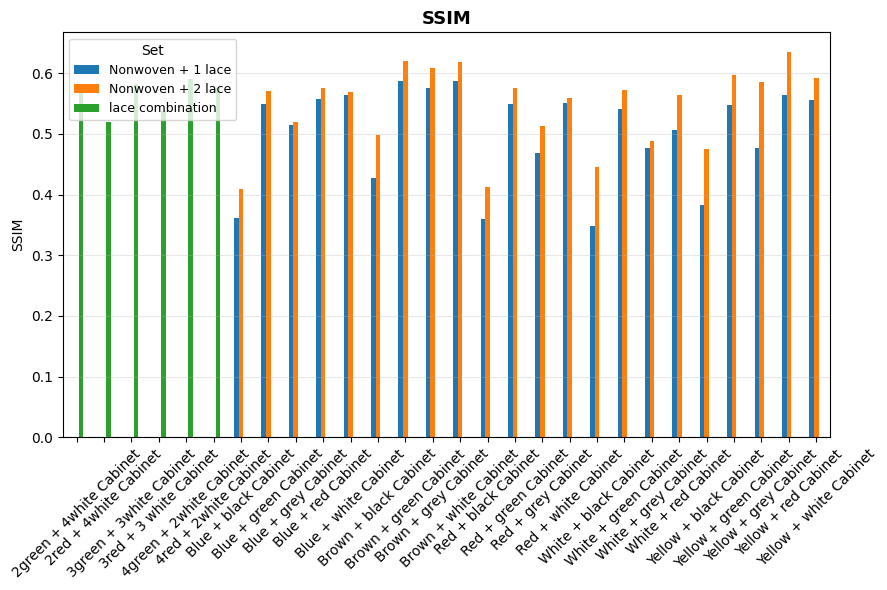

Saved SSIM comparison plot to /content/drive/MyDrive/Master/image_metrics_SSIM.png


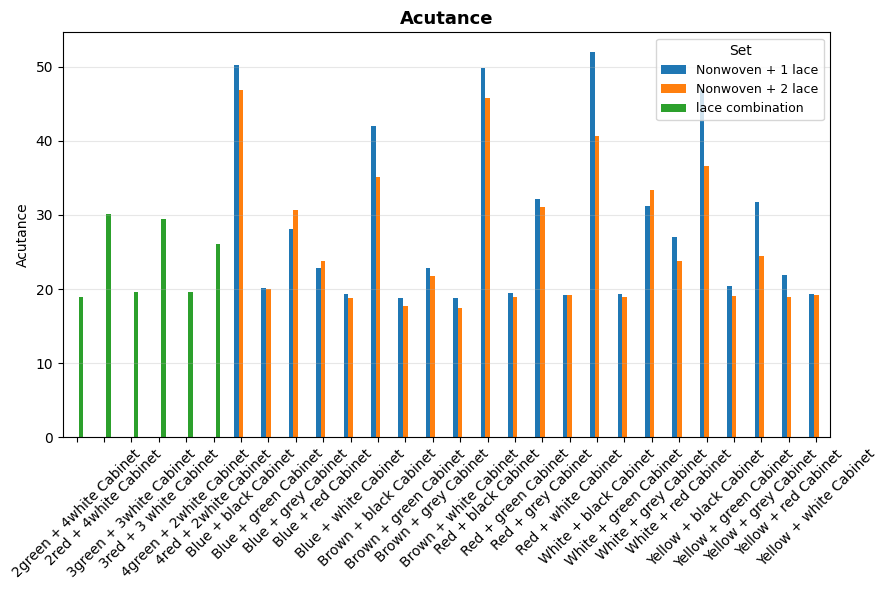

Saved Acutance comparison plot to /content/drive/MyDrive/Master/image_metrics_Acutance.png


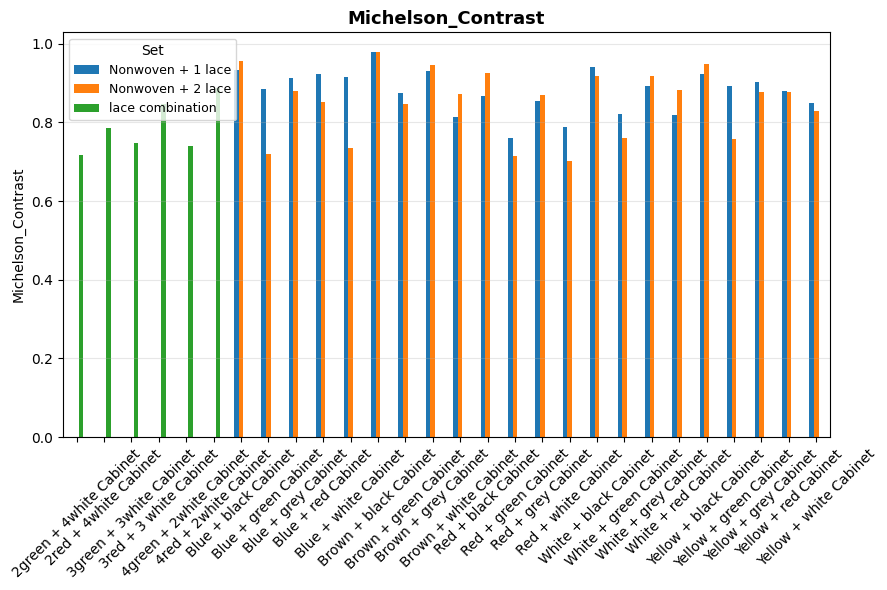

Saved Michelson_Contrast comparison plot to /content/drive/MyDrive/Master/image_metrics_Contrast.png


In [ ]:
 """
Compute SSIM, Edge Acutance, and Michelson Contrast for 3 sets of images,
and compare the sets against each other.

Two of the sets use identical filenames (e.g. both have "White cabinet.JPG"),
but the images themselves differ -- they were captured in different
sessions/folders. Filenames alone can't tell the sets apart, so each set
is defined by its own FOLDER, and every result is tagged with a `Set`
label. That label -- not the filename -- is what keeps the two
identically-named sets distinct throughout the analysis and the output
table/plots.

You do NOT need to list every image filename by hand: each set's fabric
images are discovered automatically by scanning its folder. Only the
reference (no-fabric) filename needs to be named explicitly, since it has
to be excluded from the "fabric images" list and used separately as the
comparison baseline.
"""

import os
import glob
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim_func

# ---------------------------------------------------------------
# CONFIG - edit these
# ---------------------------------------------------------------
# Each set = its own folder + its own reference filename. Fabric images are
# auto-discovered from the folder (everything except the reference).

IMAGE_EXTENSIONS = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")

SETS = [
    {
        "set_name": "Nonwoven + 1 lace",
        "folder": "/content/drive/MyDrive/Master/Images 2th September((nonwoven + 1 layer lace)",
        "reference": "/content/drive/MyDrive/Master/Images 6th September(nonwoven + 2 layer lace)/No fabric cabinet.JPG",
    },
    {
        "set_name": "Nonwoven + 2 lace",   # <- edit to your actual second session name
        "folder": "/content/drive/MyDrive/Master/Images 6th September(nonwoven + 2 layer lace)",
        "reference": "/content/drive/MyDrive/Master/Images 6th September(nonwoven + 2 layer lace)/No fabric cabinet.JPG",
    },
    {
        "set_name": "lace combination",      # <- edit to your actual third session name
        "folder": "/content/drive/MyDrive/Master/Images 6th September(combination of lace fabrics)",
        "reference": "/content/drive/MyDrive/Master/Images 6th September(nonwoven + 2 layer lace)/No fabric cabinet.JPG",
    },
]

# ROI proportions -- same convention as before (fraction of image width/height)
ROI_FRAC = dict(x=0.25, y=0.55, w=0.50, h=0.40)

OUTPUT_FILE = "/content/drive/MyDrive/Master/image_metrics_by_set.xlsx"
PLOT_FILE   = "/content/drive/MyDrive/Master/image_metrics_by_set.png"

# ---------------------------------------------------------------
# HELPERS
# ---------------------------------------------------------------
def find_fabric_images(folder, reference_filename):
    """
    Scan `folder` for image files (case-insensitive extensions), excluding
    the reference image and anything with 'color checker' in the name.
    No fixed count assumed -- works whether a set has 3 fabrics or 12.
    """
    candidates = []
    for ext in IMAGE_EXTENSIONS:
        candidates.extend(glob.glob(os.path.join(folder, f"*{ext}")))
        candidates.extend(glob.glob(os.path.join(folder, f"*{ext.upper()}")))
    candidates = sorted(set(candidates))

    ref_path = os.path.join(folder, reference_filename)
    fabric_paths = [
        p for p in candidates
        if os.path.abspath(p) != os.path.abspath(ref_path)
        and 'color checker' not in os.path.basename(p).lower()
    ]
    return fabric_paths


def imread_gray(path):
    """Returns None instead of raising, so the caller can skip bad files."""
    img = cv2.imread(path)
    if img is None:
        return None
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float64)


def compute_roi(img_shape, frac=ROI_FRAC):
    h, w = img_shape
    x = round(w * frac["x"])
    y = round(h * frac["y"])
    rw = round(w * frac["w"])
    rh = round(h * frac["h"])
    return x, y, rw, rh


def crop(img, roi):
    x, y, rw, rh = roi
    return img[y:y + rh, x:x + rw]


def sample_title(path):
    """'.../White cabinet.JPG' -> 'White cabinet' -- used only for display."""
    return os.path.splitext(os.path.basename(path))[0]


# ---------------------------------------------------------------
# COMPUTE METRICS FOR EACH SET
# ---------------------------------------------------------------
rows = []
skipped_all = []

for s in SETS:
    ref_path = os.path.join(s["folder"], s["reference"])
    ref_img = imread_gray(ref_path)
    if ref_img is None:
        raise FileNotFoundError(f"Could not read reference image: {ref_path}")

    roi = compute_roi(ref_img.shape)
    ref_roi = crop(ref_img, roi)

    fabric_paths = find_fabric_images(s["folder"], s["reference"])
    print(f"[{s['set_name']}] found {len(fabric_paths)} fabric image(s) in {s['folder']}")

    for img_path in fabric_paths:
        img = imread_gray(img_path)
        if img is None:
            skipped_all.append(img_path)
            continue

        img_roi = crop(img, roi)

        # Metric 1: SSIM
        ssim_val = ssim_func(img_roi, ref_roi, data_range=255,
                              gaussian_weights=True, sigma=1.5,
                              use_sample_covariance=False)

        # Metric 2: Edge Acutance -- mean Sobel gradient magnitude
        gx = cv2.Sobel(img_roi, cv2.CV_64F, 1, 0, ksize=3)
        gy = cv2.Sobel(img_roi, cv2.CV_64F, 0, 1, ksize=3)
        gmag = np.sqrt(gx**2 + gy**2)
        acutance_val = np.mean(gmag)

        # Metric 3: Michelson Contrast
        contrast_val = (img_roi.max() - img_roi.min()) / (img_roi.max() + img_roi.min())

        rows.append({
            "Set": s["set_name"],
            "Sample": sample_title(img_path),
            "SSIM": ssim_val,
            "Acutance": acutance_val,
            "Michelson_Contrast": contrast_val,
        })

        print(f"  {sample_title(img_path):25s}  "
              f"SSIM={ssim_val:.4f}  Acutance={acutance_val:.2f}  Contrast={contrast_val:.4f}")

results_df = pd.DataFrame(rows)

print(f"\nProcessed {len(rows)} image(s) total across {len(SETS)} set(s).")
if skipped_all:
    print(f"Skipped {len(skipped_all)} unreadable file(s): "
          f"{', '.join(os.path.basename(p) for p in skipped_all)}")

# ---------------------------------------------------------------
# SAVE RESULTS
# ---------------------------------------------------------------
metrics = ["SSIM", "Acutance", "Michelson_Contrast"]
set_names = [s["set_name"] for s in SETS]

PLOT_FILES = {
    "SSIM": "/content/drive/MyDrive/Master/image_metrics_SSIM.png",
    "Acutance": "/content/drive/MyDrive/Master/image_metrics_Acutance.png",
    "Michelson_Contrast": "/content/drive/MyDrive/Master/image_metrics_Contrast.png",
}

for metric in metrics:
    pivot = results_df.pivot(index="Sample", columns="Set", values=metric)
    pivot = pivot.reindex(columns=set_names)  # keep consistent set order/colors

    fig, ax = plt.subplots(figsize=(9, 6))
    pivot.plot(kind="bar", ax=ax)
    ax.set_title(metric, fontsize=13, fontweight="bold")
    ax.set_ylabel(metric)
    ax.set_xlabel("")
    ax.tick_params(axis='x', rotation=45)
    ax.legend(title="Set", fontsize=9)
    ax.grid(True, alpha=0.3, axis='y')

    plt.tight_layout()
    plt.savefig(PLOT_FILES[metric], dpi=150, bbox_inches="tight")
    plt.show()

    print(f"Saved {metric} comparison plot to {PLOT_FILES[metric]}")